<a href="https://colab.research.google.com/github/Annette-1/SIMULACION-II/blob/main/Euler_Maruyama_MBG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <span style="color:magenta;"> **Método de Euler–Maruyama para el movimiento geométrico browniano** </span>

<span style="color:teal;">**Nombre:** </span> Jerónimo López Annette Michelle

<span style="color:magenta;">**Objetivo.** Implementar el método de Euler–Maruyama para aproximar la solución de una ecuación diferencial estocástica (EDE), compararla con su solución exacta y estimar el error mediante simulaciones Monte Carlo.</span>

Se estudiará la EDE:

$$
dY_t=rY_t\,dt+\sigma Y_t\,dB_t,\qquad Y_0=1,
$$

donde $B_t$ es un movimiento browniano estándar.



## <span style="color:purple;">**Datos del problema**</span>

Se utilizan los parámetros indicados en el ejercicio:

| Parámetro | Valor | Descripción |
|---|---:|---|
| \(r\) | 0.1 | Coeficiente de crecimiento |
| \(\sigma\) | 0.3 | Volatilidad |
| \(\Delta t\) | 0.2 | Tamaño del paso |
| \(T\) | 8 | Tiempo final |
| \(Y_0\) | 1 | Condición inicial |

El número de pasos de la malla es:

$$
n=\frac{T}{\Delta t}=\frac{8}{0.2}=40.
$$


In [26]:
#Importamos librerias
import numpy as np
import matplotlib.pyplot as plt

## <span style="color:purple;">**Fundamento del método de Euler–Maruyama**</span>

Para una EDE general,

$$
dY_t=f(t,Y_t)\,dt+g(t,Y_t)\,dB_t,
$$

la aproximación de Euler–Maruyama se define por:

$$
W_{i+1}=W_i+f(t_i,W_i)\Delta t
+g(t_i,W_i)\Delta B_i.
$$

En este problema:

$$
f(t,W)=rW,\qquad g(t,W)=\sigma W.
$$

Por tanto, la fórmula que se programa es:

$$
\boxed{W_{i+1}=W_i+rW_i\Delta t+\sigma W_i\Delta B_i}
$$

Los incrementos del movimiento browniano se generan mediante:

$$
\Delta B_i=\sqrt{\Delta t}\,Z_i,\qquad Z_i\sim N(0,1).
$$


## <span style="color:purple;">**Solución exacta**</span>

$$
\boxed{
Y_t=Y_0\exp\left[\left(r-\frac{\sigma^2}{2}\right)t+\sigma B_t\right]
}
$$




Ambas soluciones usan **los mismos incrementos brownianos**, así que el error se mide trayectoria a trayectoria:

$$\text{MAE}=\frac1M\sum_{j=1}^M |Y_T^{(j)}-W_T^{(j)}|,\qquad \text{RMSE}=\sqrt{\frac1M\sum_{j=1}^M (Y_T^{(j)}-W_T^{(j)})^2}$$

In [27]:
r, sigma, y0, T, dt = 0.1, 0.3, 1.0, 8.0, 0.2 # Parámetros del problema

In [28]:
def simular(dt, M, rng):
    """Devuelve t, W (Euler–Maruyama) y Y (exacta), con forma (M, n+1), usando el mismo browniano."""
    n = int(round(T / dt))
    t = np.linspace(0, T, n + 1)
    dB = np.sqrt(dt) * rng.standard_normal((M, n))
    B = np.hstack([np.zeros((M, 1)), dB.cumsum(axis=1)])
    W = y0 * np.hstack([np.ones((M, 1)), np.cumprod(1 + r*dt + sigma*dB, axis=1)])  # W_{i+1} = W_i (1 + r dt + sigma dB_i)
    Y = y0 * np.exp((r - 0.5*sigma**2) * t + sigma * B)
    return t, W, Y

Defininmos la función de error

In [29]:
def error_abs(W, Y):
    e = np.abs(Y[:, -1] - W[:, -1])
    return e.mean(), np.sqrt(np.mean(e**2)), e   # MAE, RMSE, errores individuales

### <span style="color:blue;">**Comparación gráfica: exacta vs. Euler–Maruyama**</span>

La gráfica muestra la trayectoria aproximada por Euler–Maruyama y la trayectoria exacta asociada al mismo movimiento browniano. A continuación obseravamos esto mismo pero con mas trayectorias simuladas

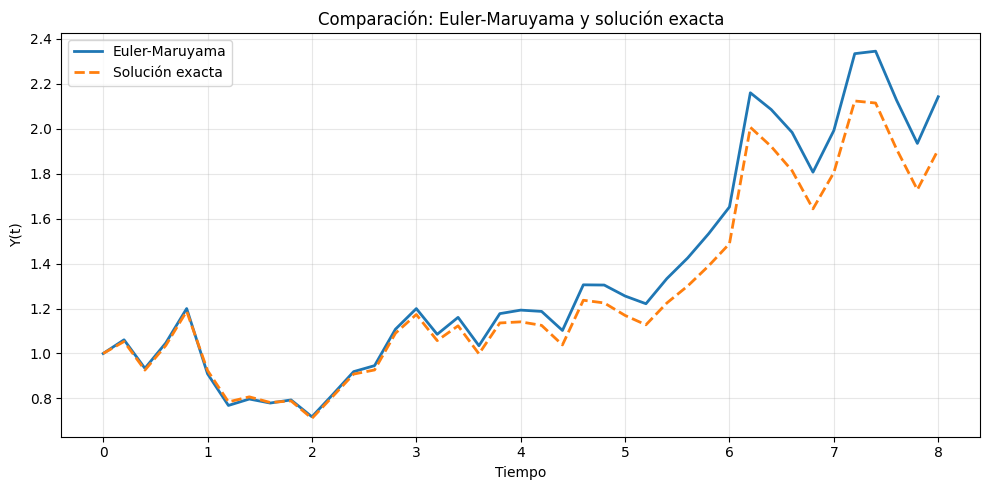

In [30]:
rng = np.random.default_rng(42)
K = 1                                   # número de trayectorias
t, W, Y = simular(dt, K, rng)

plt.figure(figsize=(10, 5))
plt.plot(t, W[0], label="Euler-Maruyama", linewidth=2)
plt.plot(t, Y[0], "--", label="Solución exacta", linewidth=2)
plt.xlabel("Tiempo")
plt.ylabel("Y(t)")
plt.title("Comparación: Euler-Maruyama y solución exacta")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## <span style="color:purple;">**Error**</span>

En el tiempo final se calcula el error absoluto:

$$
e_T=|Y_T-W_n|.
$$

Este valor corresponde únicamente a la trayectoria simulada; por ello puede cambiar si se modifica la semilla aleatoria.

Y para varias trayectorias es:

$$\text{MAE}=\frac1M\sum_{j=1}^M |Y_T^{(j)}-W_T^{(j)}|,\qquad \text{RMSE}=\sqrt{\frac1M\sum_{j=1}^M (Y_T^{(j)}-W_T^{(j)})^2}$$

Error con Monte Carlo en $T=8$ ($M=200{,}000$ realizaciones)

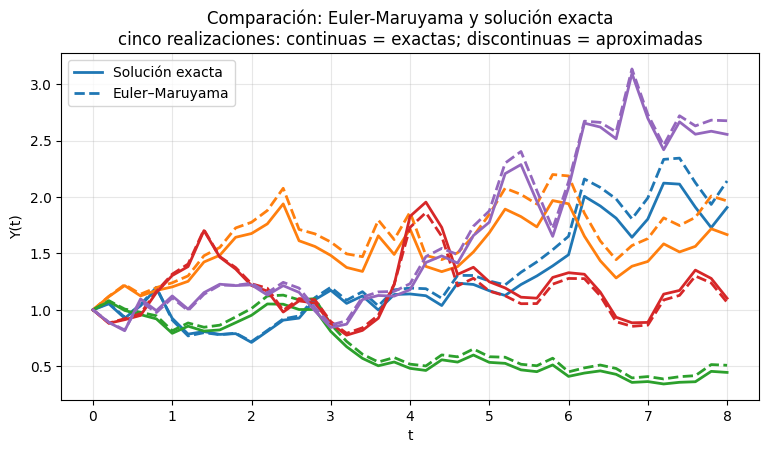

Trayectoria 1: EM = 2.141475 | Exacta = 1.906657 | |error| = 0.234818
Trayectoria 2: EM = 1.964998 | Exacta = 1.666486 | |error| = 0.298512
Trayectoria 3: EM = 0.508742 | Exacta = 0.445517 | |error| = 0.063225
Trayectoria 4: EM = 1.066174 | Exacta = 1.102456 | |error| = 0.036282
Trayectoria 5: EM = 2.675368 | Exacta = 2.554438 | |error| = 0.120930
|error| promedio = 0.150753


In [31]:
rng = np.random.default_rng(42)
K = 5                                   # número de trayectorias
t, W, Y = simular(dt, K, rng)

plt.figure(figsize=(9, 4.5))
for k, c in enumerate(plt.cm.tab10.colors[:K]):
    plt.plot(t, Y[k], color=c, lw=2, label="Solución exacta" if k == 0 else None)
    plt.plot(t, W[k], "--", color=c, lw=2, label="Euler–Maruyama" if k == 0 else None)
plt.xlabel("t"); plt.ylabel("Y(t)"); plt.title("Comparación: Euler-Maruyama y solución exacta\ncinco realizaciones: continuas = exactas; discontinuas = aproximadas")
plt.grid(alpha=.3); plt.legend(); plt.show()

err = np.abs(Y[:, -1] - W[:, -1])
for k in range(K):
    print(f"Trayectoria {k+1}: EM = {W[k,-1]:.6f} | Exacta = {Y[k,-1]:.6f} | |error| = {err[k]:.6f}")
print(f"|error| promedio = {err.mean():.6f}")



## <span style="color:purple;">**Histograma de los errores**</span>

El histograma permite observar cómo se distribuyen las diferencias $Y_T-W_n$entre las simulaciones. La distribución no tiene por qué ser simétrica.


Media exacta:         2.225190   (teórica: 2.225541)
Media Euler–Maruyama: 2.209010
Error absoluto medio (MAE): 0.141090
Raíz del error cuadrático medio (RMSE): 0.264296


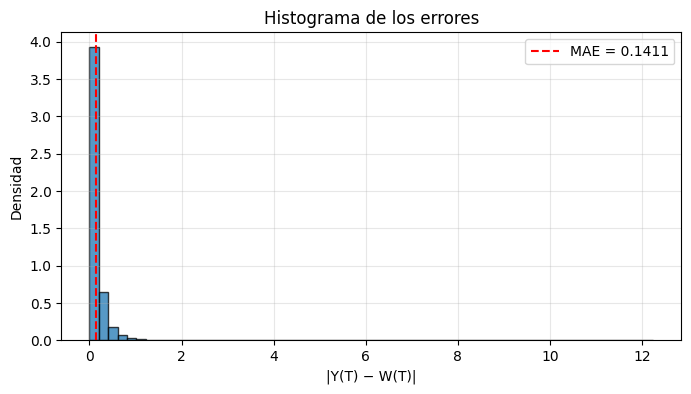

In [32]:
M = 200_000
t, W, Y = simular(dt, M, np.random.default_rng(123))
mae, rmse, e = error_abs(W, Y)

print(f"Media exacta:         {Y[:,-1].mean():.6f}   (teórica: {y0*np.exp(r*T):.6f})")
print(f"Media Euler–Maruyama: {W[:,-1].mean():.6f}")
print(f"Error absoluto medio (MAE): {mae:.6f}")
print(f"Raíz del error cuadrático medio (RMSE): {rmse:.6f}")

plt.figure(figsize=(8, 4))
plt.hist(e, bins=60, density=True, edgecolor="k", alpha=.75)
plt.axvline(mae, ls="--", c="r", label=f"MAE = {mae:.4f}")
plt.xlabel("|Y(T) − W(T)|"); plt.ylabel("Densidad"); plt.title("Histograma de los errores")
plt.grid(alpha=.3); plt.legend(); plt.show()

## <span style="color:purple;">**Análisis de Convergencia (Gráfica Log-Log)**</Span>

El método de Euler–Maruyama tiene un orden de convergencia fuerte de $0.5$. Esto significa que el error disminuye proporcionalmente a $\sqrt{\Delta t}$ (es decir, $\mathcal{O}(\Delta t^{0.5})$).

Para verificar esto empíricamente, calcularemos el error para diferentes valores de $\Delta t$ y graficaremos los resultados en una escala log-log. Si la relación es de la forma $\text{Error} = C(\Delta t)^p$, entonces en una escala logarítmica tendremos una relación lineal:

$$\log(\text{Error}) = \log(C) + p \log(\Delta t)$$

donde la pendiente $p$ representa el orden de convergencia.

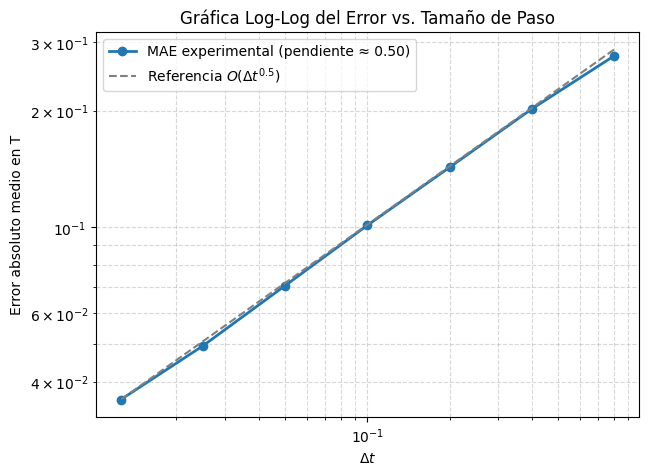

Orden de convergencia estimado: 0.497


In [33]:
dts = np.array([0.8, 0.4, 0.2, 0.1, 0.05, 0.025, 0.0125])
rng = np.random.default_rng(2024)
maes = np.array([error_abs(*simular(h, 20_000, rng)[1:])[0] for h in dts])
p, logC = np.polyfit(np.log(dts), np.log(maes), 1)

plt.figure(figsize=(7, 5))
plt.loglog(dts, maes, "o-", lw=2, label=f"MAE experimental (pendiente ≈ {p:.2f})")
plt.loglog(dts, maes[-1]*(dts/dts[-1])**0.5, "--", c="gray", label=r"Referencia $O(\Delta t^{0.5})$")
plt.xlabel(r"$\Delta t$"); plt.ylabel("Error absoluto medio en T")
plt.title("Gráfica Log-Log del Error vs. Tamaño de Paso"); plt.grid(True, which="both", ls="--", alpha=.5); plt.legend(); plt.show()
print(f"Orden de convergencia estimado: {p:.3f}")

##  <span style="color:purple;">**Simulación de varias trayectorias con múltiples tamaños de paso y su promedio ($\Delta t$ vs. $\mathbb E[Y_t]=Y_0e^{rt}$)**</span>

 A continuación, simularemos $M = 1000$ trayectorias independientes para distintos valores de $\Delta t$. Para cada $\Delta t$, calcularemos el promedio temporal de todas las trayectorias simuladas para observar cómo el promedio numérico converge hacia el comportamiento esperado.

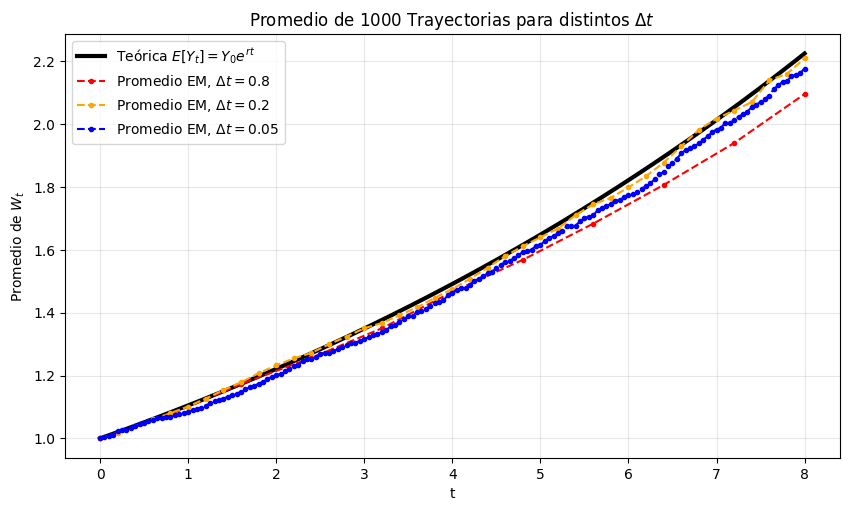

In [34]:
rng = np.random.default_rng(42)
M_trayectorias = 1000
tf = np.linspace(0, T, 200)
plt.figure(figsize=(10, 5.5))
plt.plot(tf, y0*np.exp(r*tf), "k", lw=3, label=r"Teórica $E[Y_t]=Y_0e^{rt}$")
for h, c in zip([0.8, 0.2, 0.05], ["red", "orange", "blue"]):
    t, W, _ = simular(h, M_trayectorias, rng)
    plt.plot(t, W.mean(axis=0), "o--", c=c, ms=3, label=rf"Promedio EM, $\Delta t={h}$")
plt.xlabel("t"); plt.ylabel(r"Promedio de $W_t$"); plt.title(rf"Promedio de {M_trayectorias} Trayectorias para distintos $\Delta t$")
plt.grid(alpha=.3); plt.legend(); plt.show()

<span style="color:blue;">**Interpretación**</span>

El método de Euler–Maruyama aproxima la solución de la ecuación diferencial estocástica mediante una malla temporal y valores aleatorios que representan los incrementos del movimiento browniano.

La comparación de una trayectoria permite observar la diferencia entre la aproximación numérica y la solución exacta para una realización particular. Por otra parte, la simulación Monte Carlo permite estimar el error promedio y el error cuadrático medio sobre un conjunto amplio de trayectorias.

## <span style="color:magenta;">**Conclusión**</span>

Euler–Maruyama es un método sencillo para aproximar ecuaciones diferenciales estocásticas. En general, reducir el tamaño del paso temporal mejora la precisión, aunque requiere más cálculos. Los valores MAE y RMSE obtenidos cuantifican el error al tiempo final \(T=8\) para los parámetros establecidos.

El MAE y el RMSE estiman el error fuerte de Euler–Maruyama comparando trayectorias acopladas. Al reducir $\Delta t$ el error baja con pendiente cercana a $0.5$ en la gráfica log–log, y el promedio de las trayectorias se acerca a $\mathbb E[Y_t]=Y_0e^{rt}$.

Los valores exactos dependen de la semilla y del número de realizaciones.